# Mouche — 2PCF de la distribution spatiale des neurones (3D)

**Même protocole que le ver de Presigny** (`fake_world-main/notebooks/2pcf_worm.ipynb`) :
charger un nuage de points, délimiter le domaine, comparer à un catalogue aléatoire
tiré dans ce domaine, et estimer ξ(r) par Landy-Szalay (schéma des catalogues scindés
de Keihänen et al. 2019). Le 8ᵉ système du projet est donc un **connectome**, pas un
pays.

**Les données.** `data/fly_neuron_net/neurons.zip` — 238 909 positions de noyaux de
neurones de la drosophile (FlyWire), coordonnées `x, y, z` en **nanomètres**. Extrait
le 22/07/2026 avec une version du `scripts/extract_fruitfly.py` de Presigny.

**Ce qui change par rapport au ver, et pourquoi ce notebook ne réutilise pas les
fonctions 2D telles quelles.** Le pipeline historique est écrit pour des cartes ; sur
un cerveau il faut trois adaptations, sinon le calcul tourne mais mesure autre chose :

| Piège | Le code 2D fait | Conséquence sur la mouche |
|---|---|---|
| `gdf.get_coordinates()` | renvoie `(x, y)`, **sans z**, sans avertissement | on mesure la 2PCF de l'**ombre** du cerveau, pas du cerveau |
| `gdf_edge.sample_points()` | tire dans un polygone **plan** | le catalogue aléatoire ne remplit pas le volume ⇒ ξ n'a plus de dénominateur valide |
| `distance.pdist(coord)` | matrice de toutes les paires | 2.4·10¹⁰ paires ici : impossible en mémoire |

Les fonctions ajoutées en fin de [`src/methods_two_point_correlation.py`](../src/methods_two_point_correlation.py)
(`load_points_3d`, `sample_in_hull`, `pair_counts`, `compute_two_point_correlation_nd`,
`PCF_with_variance_nd`) reprennent exactement l'estimateur de Presigny —
`compute_LS_correlation_2019` est appelée telle quelle — mais comptent les paires par
**double KD-tree** et tirent l'aléatoire dans l'**enveloppe convexe 3D**.

**Plan.** (1) données et géométrie · (2) les trois pièges, vérifiés sur pièce ·
(3) contrôle : un catalogue aléatoire doit donner ξ ≈ 0 · (4) la 2PCF des neurones ·
(5) fit en loi de puissance et dimension de corrélation · (6) la même ξ relue en 3D,
sans formule · (7) ce qu'aurait donné le code 2D · (8) limites · (9) silhouettes pour le
futur fit Soneira-Peebles · (10) sauvegarde.

In [1]:
import sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, cKDTree
from scipy.optimize import curve_fit

ROOT = Path.cwd().resolve().parent           # racine fake_world_paper_july_2026/
sys.path.insert(0, str(ROOT / "src"))
import methods_two_point_correlation as mtpc
import save_load_pickle as slp

# Palette Okabe-Ito, cohérente avec les notebooks 01-04
C = {"data": "#000000", "fly": "#0072B2", "proj": "#D55E00",
     "random": "#999999", "fit": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

SEED = 42
rng = np.random.default_rng(SEED)
NM = 1e3                                     # 1 µm = 1000 nm, pour l'affichage
DATA = ROOT / "data" / "fly_neuron_net" / "neurons.zip"
print("données :", DATA, "|", f"{DATA.stat().st_size/1e6:.1f} Mo")

données : data/fly_neuron_net/neurons.zip | 8.8 Mo


## 1. Les données et le domaine

`load_points_3d` construit un GeoDataFrame de `POINT Z` — l'équivalent du `load_worm`
de Presigny, avec les colonnes `x, y, z` du CSV.

### Le domaine : pourquoi il en faut un

ξ(r) mesure un **excès** de voisins par rapport à « pas de structure ». Encore faut-il dire
où le hasard aurait le droit de mettre ses points : sans domaine, la question n'a pas de
sens. En 2D ce rôle est tenu par la frontière du pays (`gdf_edge` dans les notebooks
01-04) ; en 3D il faut un **volume**.

### Ce qu'est une enveloppe convexe

C'est le **plus petit ensemble convexe contenant tous les points** — « convexe » voulant
dire que le segment joignant deux points quelconques de l'ensemble y reste entièrement.
Autrement dit : la forme sans creux ni rentrant qui emballe le nuage au plus juste.
L'image mécanique est exacte — en 2D, un élastique lâché autour de punaises plantées aux
positions des points ; en 3D, un film thermorétractable qu'on fait rétrécir sur le nuage.
Il vient épouser les points les plus extérieurs et enjambe tout le reste.

`scipy.spatial.ConvexHull` en renvoie quatre choses, toutes utilisées ici :

| attribut | ce que c'est | à quoi il sert |
|---|---|---|
| `.vertices` | les points du nuage qui touchent la surface (439 ici) | tracer l'enveloppe |
| `.simplices` | les faces triangulaires de la surface | l'affichage 3D du § 1 |
| `.equations` | les demi-espaces `A·x + b ≤ 0` dont l'**intersection est l'enveloppe**, un par face | le test « dedans / dehors » de `sample_in_hull` |
| `.volume` | le volume enclos | la densité de référence |

C'est la ligne `.equations` qui fait le travail : être dans l'enveloppe, c'est satisfaire
*toutes* les inégalités à la fois, ce qui se teste en une multiplication matricielle sur
tout un lot de points tirés — d'où le tirage par rejet de `sample_in_hull`.

### Ce que ça coûte

`data/fly_neuron_net/fruitfly.geojson` existe, mais c'est l'enveloppe convexe **planaire**
produite par `shapely` (les sommets portent un z, mais l'enveloppe est calculée dans le
plan) : inutilisable comme volume. On recalcule donc l'enveloppe convexe **3D** avec
`scipy.spatial.ConvexHull`, à partir des données elles-mêmes.

Le mot « convexe » est le prix à payer : **un cerveau n'est pas convexe**. Les creux entre
lobes optiques et cerveau central sont enjambés par le film et comptés comme habitables.
L'enveloppe fait ici 44 % de la boîte englobante — bien mieux que la boîte, donc — mais
28 % des points aléatoires y tombent à plus de 10 µm de tout neurone (§ 8), c'est-à-dire
dans du vide. Le dénominateur RR est d'autant dilué et ξ s'en trouve gonflé à toutes les
échelles. C'est le même biais que la frontière d'un pays en 2D, en plus marqué ; la § 8 le
quantifie et propose les deux garde-fous (alpha-shape, ou même domaine imparfait des deux
côtés de la comparaison).

In [2]:
gdf = mtpc.load_points_3d(DATA)
X = mtpc.coords_3d(gdf)                      # (N, 3) — include_z=True

hull = ConvexHull(X)
extent = X.max(axis=0) - X.min(axis=0)
bbox_vol = np.prod(extent)
rmin = mtpc.compute_rmin_nd(X)

print(f"N = {len(X):,} neurones".replace(",", " "))
print(f"étendue (x, y, z) = {np.round(extent/NM, 1)} µm")
print(f"enveloppe convexe 3D : {len(hull.vertices)} sommets, "
      f"volume {hull.volume/NM**3:.3e} µm³ "
      f"({100*hull.volume/bbox_vol:.0f} % de la boîte englobante)")
print(f"positions dupliquées : {int(pd.DataFrame(X).duplicated().sum()):,}".replace(",", " "))
print(f"distance moyenne au plus proche voisin (rmin) = {rmin/NM:.2f} µm")
print(f"pas de la grille en z : {np.gcd.reduce(np.unique(X[:, 2]).astype(np.int64))} nm "
      f"(épaisseur de coupe, négligeable devant rmin)")

N = 238 909 neurones
étendue (x, y, z) = [815.3 391.5 278.5] µm
enveloppe convexe 3D : 439 sommets, volume 3.930e+07 µm³ (44 % de la boîte englobante)
positions dupliquées : 13 321
distance moyenne au plus proche voisin (rmin) = 1.96 µm
pas de la grille en z : 40 nm (épaisseur de coupe, négligeable devant rmin)


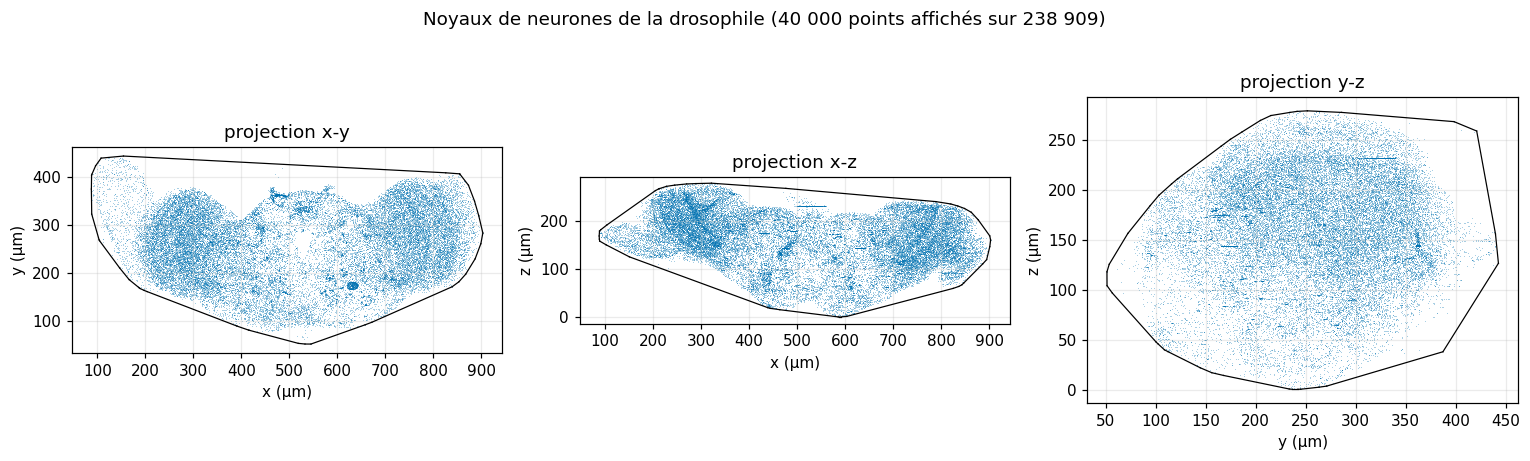

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
sub = X[rng.choice(len(X), 40000, replace=False)]     # sous-échantillon pour l'affichage
for ax, (i, j), lbl in zip(axes, [(0, 1), (0, 2), (1, 2)], ["x-y", "x-z", "y-z"]):
    ax.scatter(sub[:, i]/NM, sub[:, j]/NM, s=0.4, alpha=0.25, color=C["fly"], lw=0)
    h2 = ConvexHull(X[:, [i, j]])
    for s in h2.simplices:
        ax.plot(X[s, i]/NM, X[s, j]/NM, color=C["data"], lw=0.8)
    ax.set_xlabel(f"{lbl[0]} (µm)"); ax.set_ylabel(f"{lbl[-1]} (µm)")
    ax.set_title(f"projection {lbl}"); ax.set_aspect("equal")
fig.suptitle("Noyaux de neurones de la drosophile (40 000 points affichés sur 238 909)")
fig.tight_layout(); plt.show()

### Le nuage en volume

Les trois panneaux ci-dessus sont des **ombres** : chacun écrase une dimension. La figure
suivante montre l'objet lui-même, dans l'enveloppe convexe qui servira de domaine au
catalogue aléatoire — et, à droite, ce qu'il devient une fois aplati, c'est-à-dire ce que
le pipeline 2D reçoit réellement (piège 1). Deux neurones séparés de plus de 200 µm peuvent avoir
la même ombre : la projection ne dégrade pas les distances, elle en **fabrique de
fausses**, et rien dans la valeur de ξ ne le signalera.

Les cellules de vue tirent dans un générateur séparé (`rng_v`), pour ne pas décaler le
flux `rng` dont dépendent les chiffres des sections suivantes.

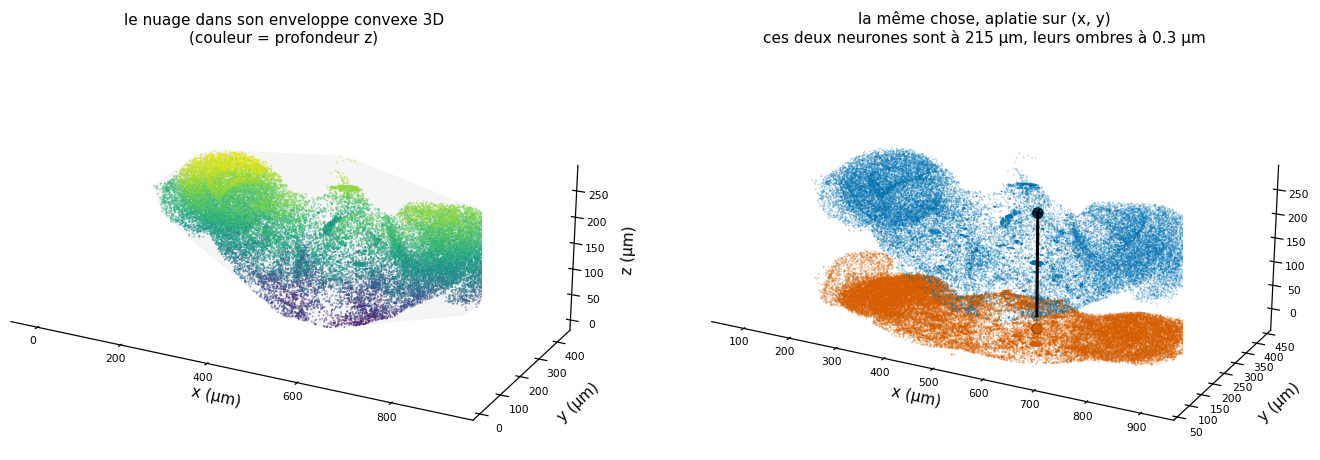

In [4]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

rng_v = np.random.default_rng(SEED + 1)      # flux dédié à l'affichage
Xu    = X / NM                               # µm
sub3  = Xu[rng_v.choice(len(Xu), 40000, replace=False)]
z0    = Xu[:, 2].min() - 25                  # plan sur lequel on projette l'ombre

def vue_3d(ax, zoom=1.45):
    ax.set_box_aspect(Xu.max(axis=0) - Xu.min(axis=0), zoom=zoom)
    ax.set_xlabel("x (µm)", labelpad=-6); ax.set_ylabel("y (µm)", labelpad=-6)
    ax.set_zlabel("z (µm)", labelpad=-8)
    ax.tick_params(labelsize=7, pad=-3); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=20, azim=-62)

fig = plt.figure(figsize=(13, 4.3))
ax = fig.add_subplot(121, projection="3d")
V = hull.points / NM
ax.add_collection3d(Poly3DCollection([V[s] for s in hull.simplices],
                                     facecolor="0.55", alpha=.045, edgecolor="none"))
ax.scatter(*sub3.T, c=sub3[:, 2], cmap="viridis", s=1.4, alpha=.55, lw=0)
ax.set_title("le nuage dans son enveloppe convexe 3D\n(couleur = profondeur z)", fontsize=10)
vue_3d(ax)

ax = fig.add_subplot(122, projection="3d")
ax.scatter(sub3[:, 0], sub3[:, 1], np.full(len(sub3), z0),
           color=C["proj"], s=1.4, alpha=.35, lw=0)                  # l'ombre
ax.scatter(*sub3.T, color=C["fly"], s=1.2, alpha=.30, lw=0)          # le nuage
# la paire dont les ombres se confondent le plus, à z le plus éloigné
paires = cKDTree(Xu[:, :2]).query_pairs(1.0, output_type="ndarray")
i, j = paires[np.argmax(np.abs(Xu[paires[:, 0], 2] - Xu[paires[:, 1], 2]))]
for k in (i, j):
    ax.plot([Xu[k, 0]] * 2, [Xu[k, 1]] * 2, [Xu[k, 2], z0], color="k", lw=.8, ls=":")
ax.plot(Xu[[i, j], 0], Xu[[i, j], 1], Xu[[i, j], 2], color="k", lw=2, zorder=20)
ax.scatter(Xu[[i, j], 0], Xu[[i, j], 1], Xu[[i, j], 2], color="k", s=45, zorder=21)
ax.scatter(Xu[[i, j], 0], Xu[[i, j], 1], [z0, z0], color=C["proj"], s=45, zorder=21,
           edgecolor="k", lw=.6)
d3 = np.linalg.norm(Xu[i] - Xu[j]); d2 = np.linalg.norm(Xu[i, :2] - Xu[j, :2])
ax.set_title(f"la même chose, aplatie sur (x, y)\nces deux neurones sont à {d3:.0f} µm, "
             f"leurs ombres à {d2:.1f} µm", fontsize=10)
vue_3d(ax)
fig.subplots_adjust(left=.01, right=.99, top=.86, bottom=.02, wspace=0)
plt.show()

## 2. Les trois pièges du passage en 3D, vérifiés sur pièce

Avant de calculer quoi que ce soit, on montre que les fonctions 2D **tournent sans
erreur** sur ces données — et donnent silencieusement autre chose que ce qu'on croit.
C'est le vrai risque : aucune exception ne signale le problème.

In [5]:
# Piège 1 : get_coordinates() laisse tomber z
xy_only = gdf.get_coordinates().to_numpy()
xyz     = gdf.get_coordinates(include_z=True).to_numpy()
print(f"piège 1 — get_coordinates()          -> shape {xy_only.shape}  (z perdu)")
print(f"          get_coordinates(include_z=True) -> shape {xyz.shape}")
d2 = np.linalg.norm(xyz[:5000, :2] - xyz[0, :2], axis=1)
d3 = np.linalg.norm(xyz[:5000] - xyz[0], axis=1)
print(f"          distances au 1er point : sous-estimation médiane de "
      f"{100*(1 - np.median(d2[1:]/d3[1:])):.0f} % si on oublie z\n")

# Piège 2 : sample_points() tire dans un plan
import geopandas as gpd
gdf_edge = gpd.read_file(ROOT / "data" / "fly_neuron_net" / "fruitfly.geojson")
flat = gdf_edge.sample_points(1000).get_coordinates(include_z=True)
print(f"piège 2 — geojson : {gdf_edge.geometry.iloc[0].geom_type}, "
      f"has_z={gdf_edge.geometry.iloc[0].has_z}")
print(f"          sample_points -> colonnes {list(flat.columns)}, "
      f"z tous nuls ou absents : {('z' not in flat) or bool(flat.get('z', pd.Series([0])).isna().all())}")
R_test = mtpc.sample_in_hull(hull, 1000, rng)
print(f"          sample_in_hull -> shape {R_test.shape}, "
      f"étendue en z {np.ptp(R_test[:, 2])/NM:.0f} µm (le volume est bien rempli)\n")

# Piège 3 : la matrice des distances
print(f"piège 3 — pdist sur {len(X):,} points = {len(X)*(len(X)-1)/2:.2e} paires "
      f"= {len(X)*(len(X)-1)/2*8/1e12:.1f} To en float64".replace(",", " "))
t0 = time.time(); _ = mtpc.pair_counts(X, np.array([0., rmin, 10*rmin]))
print(f"          pair_counts (double KD-tree) : {time.time()-t0:.1f} s, mémoire O(N)")

piège 1 — get_coordinates()          -> shape (238909, 2)  (z perdu)
          get_coordinates(include_z=True) -> shape (238909, 3)
          distances au 1er point : sous-estimation médiane de 9 % si on oublie z

piège 2 — geojson : Polygon, has_z=True
          sample_points -> colonnes ['x', 'y', 'z'], z tous nuls ou absents : True
          sample_in_hull -> shape (1000, 3), étendue en z 265 µm (le volume est bien rempli)

piège 3 — pdist sur 238 909 points = 2.85e+10 paires = 0.2 To en float64


          pair_counts (double KD-tree) : 1.3 s, mémoire O(N)


## 3. Paramètres et contrôle : un catalogue aléatoire doit donner ξ ≈ 0

Mêmes paramètres que chez Presigny (`N_run` catalogues aléatoires de `Nr_prime` points,
bins logarithmiques entre `rmin` et `rmax`), plus un paramètre imposé par la taille du
jeu : `Nsample`.

- **`rmin`** = distance moyenne au plus proche voisin (2.0 µm) : en dessous, ξ ne mesure
  que le bruit de comptage.
- **`rmax`** = 35 % de la diagonale du cerveau. Au-delà, chaque paire de points « voit »
  le bord du domaine et ξ mesure la forme de l'enveloppe, pas l'agrégation.
- **`Nsample = 20 000`** : la 2PCF est un **rapport** de densités de paires, donc
  invariante par sous-échantillonnage aléatoire (vérifié : ξ identique à 10 k, 20 k et
  40 k points, à ±0.02). On tire `N_real` sous-échantillons, ce qui donne en prime la
  dispersion. Sans cela, une réalisation sur les 238 909 points coûte ~90 s de comptage
  au lieu de ~4 s, pour le même ξ.

**Le contrôle.** On applique toute la chaîne à un catalogue aléatoire tiré dans la même
enveloppe : par construction ξ doit être nul partout. C'est ce qui valide à la fois
l'estimateur et le tirage volumique — si `sample_in_hull` remplissait mal le domaine, ce
test le montrerait.

In [6]:
N_run    = 4          # catalogues aléatoires par réalisation
Nr_prime = 20000      # points par catalogue
N_real   = 8          # réalisations (dispersion)
Nsample  = 20000      # sous-échantillon de données par réalisation
nbins    = 21
rmax     = 0.35 * np.linalg.norm(extent)

r_edges = np.logspace(np.log10(rmin), np.log10(rmax), nbins)
r_c     = np.sqrt(r_edges[:-1] * r_edges[1:])        # centres géométriques des bins
print(f"rmin = {rmin/NM:.2f} µm | rmax = {rmax/NM:.1f} µm | {nbins-1} bins log")

t0 = time.time()
R = mtpc.sample_in_hull(hull, Nsample, rng)
xi_random = mtpc.compute_two_point_correlation_nd(R, hull, r_edges, N_run, Nr_prime, rng)
print(f"contrôle aléatoire : {time.time()-t0:.0f} s | "
      f"max|ξ| = {np.max(np.abs(xi_random)):.3f} | "
      f"médiane |ξ| = {np.median(np.abs(xi_random)):.4f}")

rmin = 1.96 µm | rmax = 331.2 µm | 20 bins log


contrôle aléatoire : 13 s | max|ξ| = 0.026 | médiane |ξ| = 0.0015


## 4. La 2PCF des neurones

In [7]:
t0 = time.time()
l_xi = mtpc.PCF_with_variance_nd(X, hull, r_edges, N_run=N_run, Nr_prime=Nr_prime,
                                 k=N_real, Nsample=Nsample, rng=rng)
xi, xi_err = l_xi.mean(axis=0), l_xi.std(axis=0)
print(f"{N_real} réalisations en {time.time()-t0:.0f} s")
print(pd.DataFrame({"r (µm)": np.round(r_c/NM, 2), "xi": np.round(xi, 3),
                    "sigma": np.round(xi_err, 3)}).to_string(index=False))

8 réalisations en 99 s
 r (µm)     xi  sigma
   2.23 11.050  0.575
   2.88  8.133  0.494
   3.73  6.009  0.281
   4.82  4.335  0.152
   6.22  3.177  0.126
   8.04  2.335  0.057
  10.39  1.768  0.042
  13.43  1.368  0.016
  17.36  1.063  0.018
  22.43  0.854  0.013
  28.99  0.690  0.012
  37.46  0.562  0.010
  48.41  0.461  0.010
  62.55  0.370  0.009
  80.84  0.271  0.005
 104.47  0.168  0.005
 135.00  0.079  0.004
 174.46 -0.014  0.001
 225.45 -0.071  0.002
 291.35 -0.115  0.003


## 5. Fit en loi de puissance et dimension de corrélation

ξ(r) = (r/r₀)^(−γ). En dimension d, l'exposant se lit comme une **dimension de
corrélation** D = d − γ : D = d signifie une distribution uniforme (ξ plat), D < d une
structure agrégée, d'autant plus « creuse » que D est petit.

⚠️ **Ne pas réutiliser `sp_helpers.fit_2pcf` ici.** Cette fonction borne le fit à
γ ≤ 1.95, ce qui encode l'hypothèse **2D** (γ < 2 ⇔ D > 0). En 3D la borne physique est
γ < 3, et une borne à 1.95 tronquerait silencieusement le résultat — exactement le
mécanisme d'artefact déjà identifié dans le draft (le γ_people = 1.95 qui était en fait
la borne du fit, pas une mesure). On refait donc le fit avec la borne de la bonne
dimension, et on vérifie que l'optimum n'est pas collé au bord.

In [8]:
def power_law(r, gamma, r0):
    return (r / r0) ** (-gamma)

def fit_power_law(r, xi, err, dim, xi_min=0.05):
    # Fit sur les bins où le signal est mesurable ; la borne sur gamma vient
    # de la dimension de l'espace (D = dim - gamma >= 0).
    m = xi > xi_min
    popt, pcov = curve_fit(power_law, r[m], xi[m],
                           sigma=np.maximum(err[m], 0.02 * xi[m]),
                           p0=[1.0, r[m][0]],
                           bounds=([1e-3, 1.0], [dim, 1e9]), maxfev=20000)
    perr = np.sqrt(np.diag(pcov))
    return dict(gamma=popt[0], r0=popt[1], gamma_err=perr[0], r0_err=perr[1],
                nbins=int(m.sum()), r_range=(r[m][0], r[m][-1]),
                at_bound=bool(popt[0] > dim - 1e-2))

fit3d = fit_power_law(r_c, xi, xi_err, dim=3)
print(f"γ  = {fit3d['gamma']:.3f} ± {fit3d['gamma_err']:.3f}"
      f"   (borné à 3 ; optimum au bord ? {fit3d['at_bound']})")
print(f"r0 = {fit3d['r0']/NM:.1f} ± {fit3d['r0_err']/NM:.1f} µm"
      f"   (erreur du fit seule ; le choix du domaine domine, cf. §8)")
print(f"D  = 3 − γ = {3 - fit3d['gamma']:.3f}")
print(f"ajusté sur {fit3d['nbins']} bins, "
      f"{fit3d['r_range'][0]/NM:.1f} → {fit3d['r_range'][1]/NM:.1f} µm")

γ  = 1.022 ± 0.036   (borné à 3 ; optimum au bord ? False)
r0 = 19.5 ± 0.7 µm   (erreur du fit seule ; le choix du domaine domine, cf. §8)
D  = 3 − γ = 1.978
ajusté sur 17 bins, 2.2 → 135.0 µm


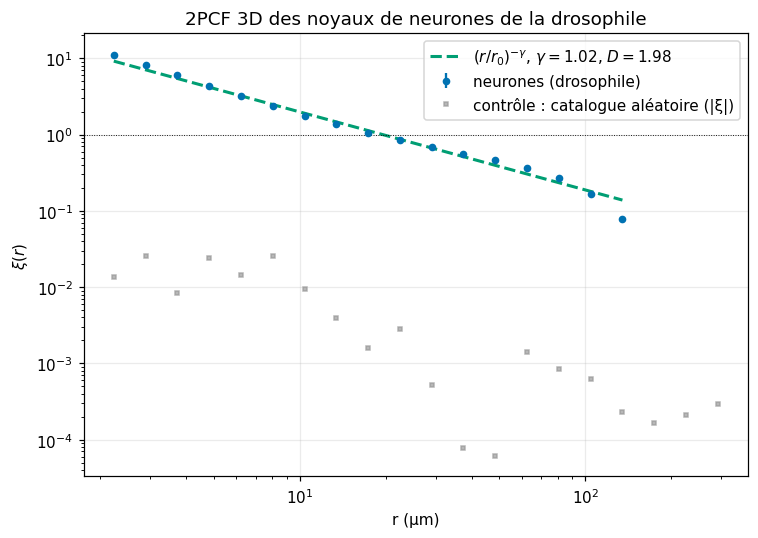

In [9]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"],
            label="neurones (drosophile)")
rr = np.logspace(np.log10(fit3d["r_range"][0]), np.log10(fit3d["r_range"][1]), 100)
ax.plot(rr/NM, power_law(rr, fit3d["gamma"], fit3d["r0"]), "--", color=C["fit"], lw=2,
        label=fr"$(r/r_0)^{{-\gamma}}$, $\gamma={fit3d['gamma']:.2f}$, $D={3-fit3d['gamma']:.2f}$")
ax.errorbar(r_c/NM, np.abs(xi_random), fmt="s", ms=3, color=C["random"], alpha=0.7,
            label="contrôle : catalogue aléatoire (|ξ|)")
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("2PCF 3D des noyaux de neurones de la drosophile")
ax.legend(); fig.tight_layout(); plt.show()

## 6. La 2PCF en 3D sans formule — l'estimateur de Davis-Peebles

ξ(r) se lit sans passer par Landy-Szalay : **c'est un excès de voisins**. On pose une
boule de rayon r sur un neurone et on compte les neurones dedans ; on pose la même boule
sur un point tiré au hasard dans le domaine et on recompte. Le rapport des deux comptages
moyens est l'**estimateur de Davis & Peebles** (*ApJ* 267, 465, 1983) :

$$1+\bar\xi(<r)\;=\;\frac{\big\langle N(<r)\big\rangle_{\text{centre = neurone}}}
                        {\big\langle N(<r)\big\rangle_{\text{centre = point aléatoire}}}
              \;=\;\frac{N_R}{N_D}\,\frac{DD(<r)}{DR(<r)}$$

Les deux écritures sont la même chose : normaliser un comptage par son nombre de centres,
c'est diviser DD par N_D et DR par N_R. Ici on tire **autant de centres de chaque type**
(`N_cent = 20 000`), donc le préfacteur vaut 1 et le rapport des moyennes *est* DD/DR.

Deux détails de lecture :

- **boules ou coquilles.** Le rapport des comptages *cumulés* donne ξ̄(<r), la moyenne de ξ
  à l'intérieur de la boule — pas ξ(r). C'est le `np.diff` sur les comptages cumulés qui
  passe aux **coquilles** et redonne ξ(r) elle-même (`xi_shell`). Le code calcule les deux :
  les boules pour le panneau de gauche, les coquilles pour celui de droite.
- **d'où viennent les centres aléatoires.** De `mtpc.sample_in_hull(hull, N_cent, rng_v)`,
  c'est-à-dire uniformément dans l'**enveloppe convexe 3D** — exactement le domaine du
  catalogue aléatoire de la § 4, et avec exactement le même défaut : l'enveloppe n'est pas
  le cerveau (§ 8).

**Ce que ce détour apporte, et ce qu'il n'apporte pas.** Davis-Peebles et Landy-Szalay
n'ont ni la même formule ni le même chemin de code — LS vaut (DD − 2DR + RR)/RR et compte
des paires entre catalogues, DP se contente de DD/DR et compte des voisins autour de
centres ; l'aléatoire fournit ici les *centres* là où LS en fait des *partenaires* de
paire. Les voir tomber d'accord teste donc réellement la normalisation de l'estimateur de
la § 4 (les préfacteurs de Keihanen, du genre qu'on rate en silence). En revanche les deux
partagent le même `hull` : **ce recoupement valide l'arithmétique, pas le choix du
domaine** — celui-là est le sujet de la § 8. Et DP, qui n'utilise pas RR, est le plus
sensible des deux au bord et aux fluctuations de densité : on le regarde pour comprendre,
on publie celui de la § 4.

boule de r = 15 µm, moyenne sur 2000 centres :
  autour d'un neurone          :  246.4 voisins
  autour d'un point quelconque :   83.3 voisins  (uniforme attendu : 85.9)
  1 + xi(<15 µm) = 2.96


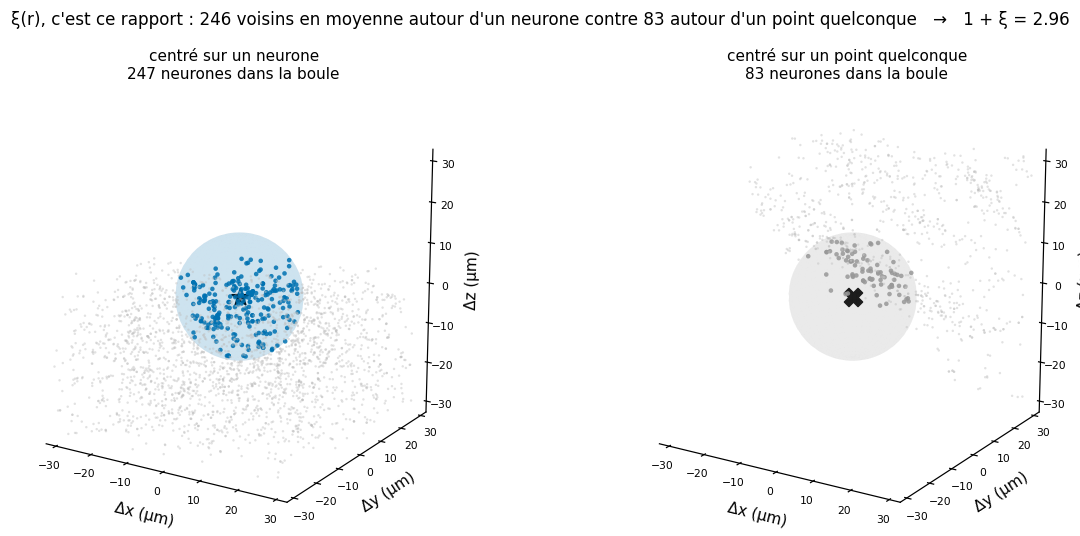

In [10]:
rng_v  = np.random.default_rng(SEED + 1)     # même flux dédié, indépendant de rng
tree   = cKDTree(X)
R_ball = 15 * NM                             # rayon de la boule, de l'ordre de r0
n_cent = 2000

cen_d = X[rng_v.choice(len(X), n_cent, replace=False)]      # centres = des neurones
cen_r = mtpc.sample_in_hull(hull, n_cent, rng_v)            # centres = des points du volume
n_d = np.array([len(a) for a in tree.query_ball_point(cen_d, R_ball, workers=-1)]) - 1
n_r = np.array([len(a) for a in tree.query_ball_point(cen_r, R_ball, workers=-1)])
print(f"boule de r = {R_ball/NM:.0f} µm, moyenne sur {n_cent} centres :")
print(f"  autour d'un neurone          : {n_d.mean():6.1f} voisins")
print(f"  autour d'un point quelconque : {n_r.mean():6.1f} voisins  "
      f"(uniforme attendu : {len(X) * 4/3*np.pi*R_ball**3 / hull.volume:.1f})")
print(f"  1 + xi(<{R_ball/NM:.0f} µm) = {n_d.mean()/n_r.mean():.2f}")

# On dessine un centre de chaque type, choisi pour porter le comptage le plus proche
# de la moyenne : ce que montre la figure est ce que mesure le rapport ci-dessus.
u, v = np.mgrid[0:2*np.pi:60j, 0:np.pi:30j]
sphere = np.array([np.cos(u)*np.sin(v), np.sin(u)*np.sin(v), np.cos(v)]) * R_ball / NM
half = 2.1 * R_ball
fig = plt.figure(figsize=(11.5, 5))
for k, (cen, n, col, mark, ttl) in enumerate([
        (cen_d[np.argmin(abs(n_d - n_d.mean()))], n_d, C["fly"], "*", "centré sur un neurone"),
        (cen_r[np.argmin(abs(n_r - n_r.mean()))], n_r, C["random"], "X", "centré sur un point quelconque")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    P = (X[tree.query_ball_point(cen, half * np.sqrt(3), workers=-1)] - cen) / NM
    P = P[(np.abs(P) <= half / NM).all(axis=1)]
    dans = np.linalg.norm(P, axis=1) <= R_ball / NM
    ax.scatter(*P[~dans].T, color="0.75", s=2.5, alpha=.45, lw=0)
    ax.scatter(*P[dans].T, color=col, s=9, alpha=.85, lw=0)
    ax.plot_surface(*sphere, color=col, alpha=.10, lw=0, shade=False)
    ax.scatter([0], [0], [0], color="k", marker=mark, s=140, zorder=20)
    ax.set_title(f"{ttl}\n{int(dans.sum())} neurones dans la boule", fontsize=10)
    L = half / NM
    ax.set_xlim(-L, L); ax.set_ylim(-L, L); ax.set_zlim(-L, L)
    ax.set_box_aspect((1, 1, 1), zoom=1.1)
    ax.set_xlabel("Δx (µm)", labelpad=-4); ax.set_ylabel("Δy (µm)", labelpad=-4)
    ax.set_zlabel("Δz (µm)", labelpad=-4)
    ax.tick_params(labelsize=7, pad=-2); ax.grid(False)
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_alpha(0)
    ax.view_init(elev=18, azim=-58)
fig.suptitle(f"ξ(r), c'est ce rapport : {n_d.mean():.0f} voisins en moyenne autour d'un neurone "
             f"contre {n_r.mean():.0f} autour d'un point quelconque   →   "
             f"1 + ξ = {n_d.mean()/n_r.mean():.2f}", fontsize=11)
fig.subplots_adjust(left=.02, right=.98, top=.84, bottom=.06, wspace=.02)
plt.show()

### Compter à tous les rayons

En répétant sur 20 000 centres de chaque type et à tous les rayons, la même image donne
deux résultats.

**La dimension se lit comme une pente.** Autour d'un point quelconque, le nombre de
voisins suit le volume de la boule : N(<r) ∝ r³. Autour d'un neurone il croît plus
lentement, et l'**excès** de voisins (données − aléatoire) croît en r^D avec D ≈ 1.9 :
c'est la dimension de corrélation, obtenue par simple comptage, sans ajuster aucune loi
de puissance — cohérente avec le D = 3 − γ = 1.98 de la §5. C'est aussi la raison pour
laquelle la projection ne peut pas retrouver la structure : dans un plan le comptage est
plafonné par r², une structure de dimension ~2 écrasée sur un espace de dimension 2 le
remplit presque, et l'excès de voisins s'évanouit — c'est exactement ce que mesure la §7
(γ tombe de 1.02 à 0.46).

**Le ξ compté à la main est celui de Landy-Szalay.** Le rapport des comptages en
coquilles reproduit la courbe de la §4 à 4 % près (écart médian) sur toute la plage
ajustée. Il ne s'en écarte franchement qu'au dernier bin, à 135 µm, où ξ est tombé à
0.08 : c'est là un rapport de deux grands nombres presque égaux, et le bord du domaine y
pèse autant que l'agrégation. D'où l'intérêt des catalogues scindés de Landy-Szalay, qui
traitent ces deux problèmes mieux que le comptage naïf — le comptage, lui, sert à
comprendre ce qu'on mesure, pas à publier le chiffre.

pente de N(<r) autour d'un point quelconque : 2.91  (volume de la boule : 3)
pente de l'excès de voisins                 : 1.89  (dimension de corrélation ; 3 - γ = 1.98)
écart au ξ de Landy-Szalay entre 2.2 et 135 µm : médiane 4 %, max 29 % (à r = 135 µm, où ξ = 0.08)


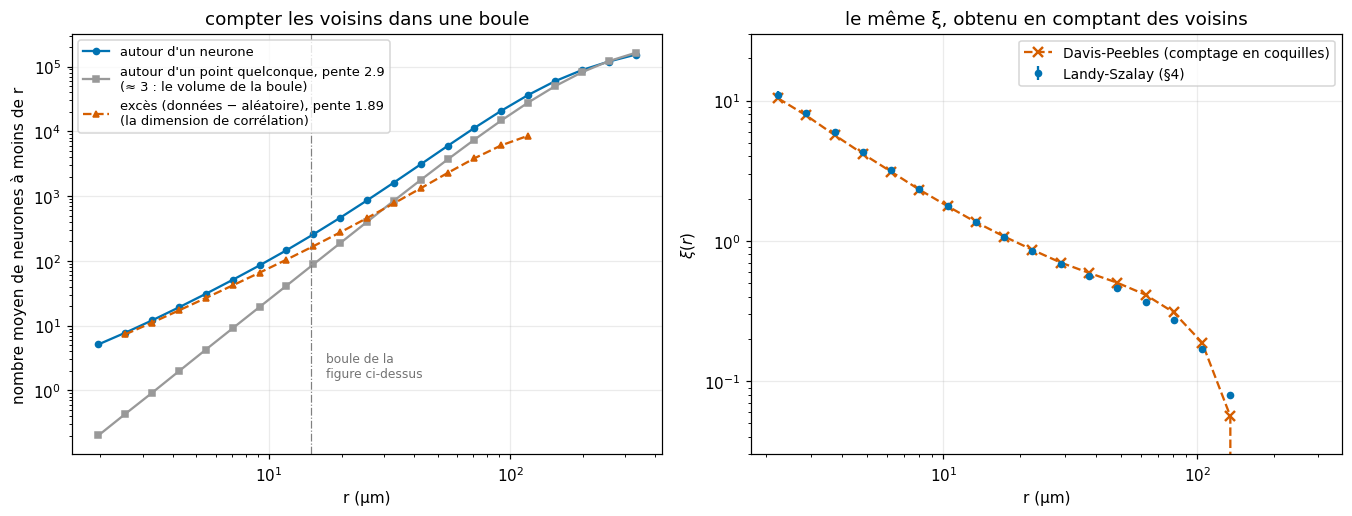

In [11]:
N_cent = 20000
cen_d  = X[rng_v.choice(len(X), N_cent, replace=False)]
cen_r  = mtpc.sample_in_hull(hull, N_cent, rng_v)
# count_neighbors donne les comptages cumulés à chaque borne de bin, en O(N log N)
cum_d = tree.count_neighbors(cKDTree(cen_d), r_edges) / N_cent - 1.0   # -1 : le centre lui-même
cum_r = tree.count_neighbors(cKDTree(cen_r), r_edges) / N_cent
xi_shell = np.diff(cum_d) / np.diff(cum_r) - 1        # version différentielle : les coquilles
excess   = cum_d - cum_r

r_lo, r_hi = fit3d["r_range"]                         # la plage ajustée à la §5
m    = (r_edges >= r_lo) & (r_edges <= r_hi) & (excess > 0)
bins = (r_c >= r_lo) & (r_c <= r_hi) & (xi > 0) & (xi_shell > 0)
D_count = np.polyfit(np.log(r_edges[m]), np.log(excess[m]), 1)[0]
p_rand  = np.polyfit(np.log(r_edges[m]), np.log(cum_r[m]), 1)[0]
ecart   = 100 * np.abs(xi_shell[bins] / xi[bins] - 1)
r_pire  = r_c[bins][np.argmax(ecart)]
print(f"pente de N(<r) autour d'un point quelconque : {p_rand:.2f}  (volume de la boule : 3)")
print(f"pente de l'excès de voisins                 : {D_count:.2f}  "
      f"(dimension de corrélation ; 3 - γ = {3 - fit3d['gamma']:.2f})")
print(f"écart au ξ de Landy-Szalay entre {r_lo/NM:.1f} et {r_hi/NM:.0f} µm : "
      f"médiane {np.median(ecart):.0f} %, max {ecart.max():.0f} % (à r = {r_pire/NM:.0f} µm, "
      f"où ξ = {xi[bins][np.argmax(ecart)]:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.8))
ax = axes[0]
ax.plot(r_edges/NM, cum_d, "o-", color=C["fly"], ms=4, label="autour d'un neurone")
ax.plot(r_edges/NM, cum_r, "s-", color=C["random"], ms=4,
        label=f"autour d'un point quelconque, pente {p_rand:.1f}\n(≈ 3 : le volume de la boule)")
ax.plot(r_edges[m]/NM, excess[m], "^--", color=C["proj"], ms=4,
        label=f"excès (données − aléatoire), pente {D_count:.2f}\n(la dimension de corrélation)")
ax.axvline(R_ball/NM, color="0.5", lw=.8, ls="-.")
ax.text(R_ball/NM*1.15, 1.6, "boule de la\nfigure ci-dessus", fontsize=8, color="0.45")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel("nombre moyen de neurones à moins de r")
ax.set_title("compter les voisins dans une boule")
ax.legend(fontsize=8.5, loc="upper left")

ax = axes[1]
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"], label="Landy-Szalay (§4)")
ax.plot(r_c/NM, xi_shell, "x--", color=C["proj"], ms=7, mew=1.6,
        label="Davis-Peebles (comptage en coquilles)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(3e-2, 3e1)
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("le même ξ, obtenu en comptant des voisins")
ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

## 7. Ce qu'aurait donné le code 2D

La démonstration décisive : on relance **le même estimateur, la même fonction**, en lui
passant simplement la projection `(x, y)` du nuage et l'enveloppe convexe 2D
correspondante — c'est-à-dire exactement ce que produit le pipeline historique appliqué
tel quel à ces données (piège 1 + piège 2 combinés). Seule la dimension de l'entrée
change.

In [12]:
X2 = X[:, :2]
hull2 = ConvexHull(X2)
t0 = time.time()
l_xi2 = mtpc.PCF_with_variance_nd(X2, hull2, r_edges, N_run=N_run, Nr_prime=Nr_prime,
                                  k=N_real, Nsample=Nsample, rng=rng)
xi2, xi2_err = l_xi2.mean(axis=0), l_xi2.std(axis=0)
fit2d = fit_power_law(r_c, xi2, xi2_err, dim=2)
print(f"projection (x,y) : {time.time()-t0:.0f} s")
print(f"  γ = {fit2d['gamma']:.3f} ± {fit2d['gamma_err']:.3f} (borné à 2), "
      f"r0 = {fit2d['r0']/NM:.1f} µm, D = 2 − γ = {2 - fit2d['gamma']:.3f}")
print(f"\ncomparaison au premier bin (r = {r_c[0]/NM:.1f} µm) : "
      f"ξ_3D = {xi[0]:.2f} contre ξ_2D = {xi2[0]:.2f} "
      f"({xi[0]/xi2[0]:.1f}× plus faible en projection)")

projection (x,y) : 45 s
  γ = 0.457 ± 0.055 (borné à 2), r0 = 3.1 µm, D = 2 − γ = 1.543

comparaison au premier bin (r = 2.2 µm) : ξ_3D = 11.05 contre ξ_2D = 0.95 (11.6× plus faible en projection)


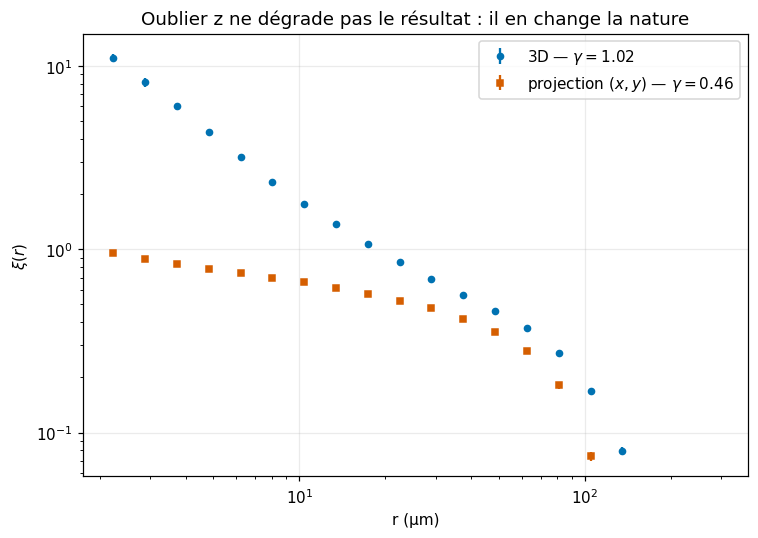

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(r_c/NM, xi, yerr=xi_err, fmt="o", ms=4, color=C["fly"],
            label=fr"3D — $\gamma={fit3d['gamma']:.2f}$")
ax.errorbar(r_c/NM, xi2, yerr=xi2_err, fmt="s", ms=4, color=C["proj"],
            label=fr"projection $(x,y)$ — $\gamma={fit2d['gamma']:.2f}$")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("r (µm)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("Oublier z ne dégrade pas le résultat : il en change la nature")
ax.legend(); fig.tight_layout(); plt.show()

## 8. Limites — ce que l'enveloppe convexe fait dire à ξ

Le catalogue aléatoire définit ce que « pas d'agrégation » veut dire. Ici il remplit
l'**enveloppe convexe**, alors que le cerveau ne l'est pas : les creux entre lobes
optiques et cerveau central reçoivent des points aléatoires là où aucun neurone ne peut
se trouver. Le dénominateur RR est donc dilué, ce qui **gonfle ξ** à toutes les échelles.

C'est le même biais que la frontière d'un pays en 2D, en plus marqué. On le quantifie
en regardant à quelle distance d'un vrai neurone tombe un point aléatoire : si
l'enveloppe collait au volume occupé, cette distance serait de l'ordre de l'espacement
entre neurones (rmin).

In [14]:
d_rand, _ = cKDTree(X).query(mtpc.sample_in_hull(hull, 50000, rng), workers=-1)
d_data, _ = cKDTree(X).query(X, k=2, workers=-1)
frac_far = np.mean(d_rand > 5 * rmin)
print(f"distance au neurone le plus proche :")
print(f"  depuis un point aléatoire : médiane {np.median(d_rand)/NM:.1f} µm")
print(f"  depuis un neurone         : médiane {np.median(d_data[:, 1])/NM:.1f} µm (= rmin)")
print(f"  {100*frac_far:.0f} % des points aléatoires sont à plus de 5·rmin "
      f"({5*rmin/NM:.0f} µm) de tout neurone : autant de volume vide "
      f"que l'enveloppe convexe compte à tort comme habitable.")

distance au neurone le plus proche :
  depuis un point aléatoire : médiane 4.9 µm
  depuis un neurone         : médiane 1.6 µm (= rmin)
  28 % des points aléatoires sont à plus de 5·rmin (10 µm) de tout neurone : autant de volume vide que l'enveloppe convexe compte à tort comme habitable.


### Combien ce choix pèse-t-il ? Trois autres domaines

Le catalogue aléatoire **est** l'hypothèse nulle : ξ mesure l'écart entre *où sont les
points* et *où ils auraient pu être*. Le domaine n'est donc pas un détail technique,
c'est la définition de « l'espace disponible ». On refait ξ avec quatre domaines pour
séparer, dans le résultat, ce qui est mesuré de ce qui est supposé.

Le domaine « voxels *c* » est l'union des cellules d'une grille de pas *c* contenant au
moins un neurone — littéralement *le plus petit espace qui contient tous les nœuds*, à
la résolution *c*.


In [15]:
# Le domaine EST l'hypothèse nulle : ξ compare où sont les points à où ils
# auraient pu être. On refait donc ξ avec quatre domaines, du plus large au plus
# serré, pour séparer ce qui est mesuré de ce qui est supposé.
rng_dom = np.random.default_rng(SEED)        # local : la cellule est reproductible seule

def sampler_hull(h):
    return lambda n, g: mtpc.sample_in_hull(h, n, g)

def sampler_voxels(cell):
    """Union des cellules d'une grille de pas `cell` contenant >= 1 neurone : le
    plus petit domaine contenant tous les noeuds, à la résolution `cell`."""
    lo = X.min(axis=0)
    keys = np.unique(np.floor((X - lo) / cell).astype(np.int64), axis=0)
    return (lambda n, g: lo + (keys[g.integers(0, len(keys), n)] + g.random((n, 3))) * cell,
            len(keys) * cell**3)

def xi_domaine(sampler, k=4):
    """Même estimateur qu'en §4 ; seul change d'où sort le catalogue aléatoire."""
    out = []
    for _ in range(k):
        sub = X[rng_dom.choice(len(X), Nsample, replace=False)]
        DD = mtpc.pair_counts(sub, r_edges)
        DR, RR = np.zeros(nbins - 1), np.zeros(nbins - 1)
        for _ in range(N_run):
            R_cat = sampler(Nr_prime, rng_dom)
            DR += mtpc.pair_counts(sub, r_edges, B=R_cat)
            RR += mtpc.pair_counts(R_cat, r_edges)
        out.append(mtpc.compute_LS_correlation_2019(DD, DR, RR, len(sub),
                                                    Nr_prime, Nr_prime * N_run))
    return np.array(out)

corners = np.array(np.meshgrid(*zip(X.min(axis=0), X.max(axis=0)))).reshape(3, -1).T
s20, v20 = sampler_voxels(20 * NM)
s05, v05 = sampler_voxels(5 * NM)
domaines = [("boîte englobante",  sampler_hull(ConvexHull(corners)), bbox_vol),
            ("enveloppe convexe", sampler_hull(hull),                hull.volume),
            ("voxels 20 µm",      s20,                               v20),
            ("voxels 5 µm",       s05,                               v05)]

print(f"{'domaine':<18}{'V/V_hull':>9}{'ξ(2.2 µm)':>11}{'γ':>17}{'r0 (µm)':>16}{'bins':>6}")
for nom, s, v in domaines:
    l_xi_d = xi_domaine(s)
    xi_d, err_d = l_xi_d.mean(axis=0), l_xi_d.std(axis=0)
    f = fit_power_law(r_c, xi_d, err_d, dim=3)
    print(f"{nom:<18}{v/hull.volume:>9.2f}{xi_d[0]:>11.2f}"
          f"{f['gamma']:>11.3f} ± {f['gamma_err']:.3f}"
          f"{f['r0']/NM:>9.1f} ± {f['r0_err']/NM:.1f}{f['nbins']:>6}")


domaine            V/V_hull  ξ(2.2 µm)                γ         r0 (µm)  bins
boîte englobante       2.26      25.00      1.038 ± 0.072     55.6 ± 6.0    17
enveloppe convexe      1.00      10.16      1.033 ± 0.043     19.2 ± 0.9    17
voxels 20 µm           0.83       8.56      1.164 ± 0.026     13.2 ± 0.3    17
voxels 5 µm            0.30       3.12      1.719 ± 0.074      5.0 ± 0.2    10


Deux enseignements, de nature différente.

- **Entre les deux domaines convexes** (boîte → enveloppe, volume ×2.26), γ ne bouge
  pas (1.038 → 1.033) alors que r₀ est divisé par 2.9. C'est le comportement attendu :
  l'amplitude de ξ est fixée par la densité moyenne n̄ = N/V, donc par le volume, tandis
  que la pente compare ξ à deux rayons et l'erreur sur n̄ s'y simplifie. **γ est mesuré,
  r₀ dépend d'une convention.**
- **En resserrant le domaine sur les données** (voxels), ξ s'effondre : 10.2 → 8.6 →
  3.1 au premier bin. C'est inévitable, et ce n'est pas un meilleur estimateur : à la
  limite où la maille tend vers rmin, le domaine *est* le nuage de points, RR = DD et
  ξ = 0 quelle que soit l'agrégation réelle. **Un domaine ajusté aux données ne peut
  pas servir à tester les données.**

⚠️ Les lignes « voxels » ne sont pas des candidates pour remplacer l'enveloppe : une
grille supprime les vrais vides inter-neuropiles, mais ajoute aussi une porosité
artificielle à l'échelle de la maille, qui écrase ξ aux petits r pour une mauvaise
raison. Elles démontrent la circularité, elles ne mesurent pas le « bon » γ — leur γ
varie d'ailleurs plus que sa barre d'erreur d'un tirage à l'autre (k = 4 réalisations
seulement).


Le seul garde-fou qui échappe à cette circularité est un domaine défini
**indépendamment du nuage de points** : le maillage des neuropiles FlyWire. Un
alpha-shape reste à mi-chemin — moins arbitraire qu'une grille, mais α est encore un
réglage libre qui, comme la maille ci-dessus, fixe le résultat. À défaut, comparer le
modèle SP aux données **avec le même domaine imparfait** des deux côtés : le biais
s'annule alors en grande partie, ce qui est la logique déjà retenue dans le reste du
projet.

## 9. Silhouette : les η candidats pour le futur fit Soneira-Peebles

Comme dans `2pcf_worm.ipynb`, on prépare le fit SP : le score de silhouette d'un
k-means donne les nombres de sous-amas η plausibles. Calculé sur un sous-échantillon
(le score est en O(n²)).

⚠️ Pour le fit lui-même, une relation devra être transposée : le notebook du ver pose
`l = eta**(1/(2-gamma))`, où le 2 est la **dimension de l'espace**. En 3D il faudra
`eta**(1/(3-gamma))`, sans quoi λ est faux dès la première itération.

silhouette : {2: np.float64(0.56), 3: np.float64(0.447), 4: np.float64(0.36), 5: np.float64(0.36), 6: np.float64(0.296), 7: np.float64(0.279), 8: np.float64(0.278), 9: np.float64(0.284), 10: np.float64(0.293), 11: np.float64(0.284), 12: np.float64(0.286)}
η candidats (5 meilleurs) : [2, 3, 5, 4, 6]


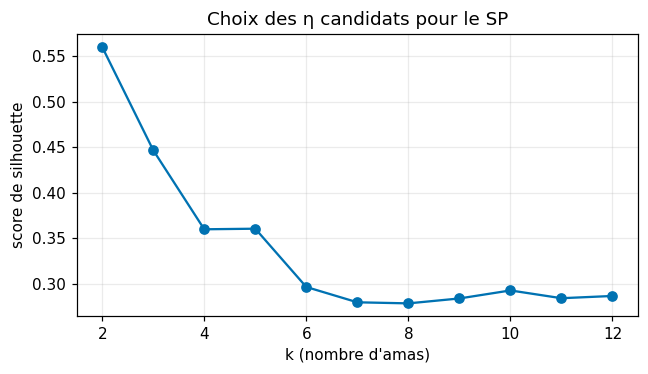

In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

S = X[rng.choice(len(X), 20000, replace=False)]
kmax, scores = 12, []
for k in range(2, kmax + 1):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(S)
    scores.append(silhouette_score(S[:5000], km.labels_[:5000]))
scores = np.array(scores)
l_cluster = (np.arange(2, kmax + 1)[np.argsort(scores)[::-1]][:5]).tolist()
print("silhouette :", dict(zip(range(2, kmax + 1), np.round(scores, 3))))
print("η candidats (5 meilleurs) :", l_cluster)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(range(2, kmax + 1), scores, "o-", color=C["fly"])
ax.set_xlabel("k (nombre d'amas)"); ax.set_ylabel("score de silhouette")
ax.set_title("Choix des η candidats pour le SP")
fig.tight_layout(); plt.show()

## 10. Sauvegarde

Deux sorties : un pickle au **format attendu par `fit_Soneira_Peebles`** (mêmes clés que
chez Presigny, plus `hull` et `dim` dont le fit 3D aura besoin), et un CSV de synthèse
dans `out/` comme les notebooks 01-04.

In [17]:
out_dir = ROOT / "out" / "fly"
out_dir.mkdir(parents=True, exist_ok=True)

# Distribution des distances, pour la divergence KL du fit SP. Presigny stocke les
# distances brutes ; ici elles seraient 2.85e10, donc on stocke l'histogramme sur
# r_edges, calculé sur un sous-échantillon plus large que celui de la 2PCF.
DD_counts = mtpc.pair_counts(X[rng.choice(len(X), 50000, replace=False)], r_edges)

d_save = {
    "r_edges": r_edges, "r_centers": r_c,
    "xi": l_xi, "xi_random": xi_random,
    "distance_distribution": DD_counts,      # comptages par bin (50 000 points)
    "fit_SP": (fit3d["gamma"], fit3d["r0"]),
    "clustering": l_cluster,
    "number_points": len(X),
    "dim": 3,                                # <- le fit SP doit utiliser 3-gamma, pas 2-gamma
    "hull_points": X[hull.vertices],         # enveloppe convexe 3D (domaine)
    "params": dict(N_run=N_run, Nr_prime=Nr_prime, N_real=N_real, Nsample=Nsample,
                   nbins=nbins, rmin=rmin, rmax=rmax, scale="log", seed=SEED),
}
pkl = out_dir / f"fly_2pcf_{N_run}_{Nr_prime}_{N_real}_{Nsample}_{nbins}"
slp.save_results(pkl, d_save)
print("->", pkl)

df = pd.DataFrame({
    "r_nm": r_c, "r_um": r_c / NM,
    "xi_3d": xi, "xi_3d_std": xi_err,
    "xi_proj_xy": xi2, "xi_proj_xy_std": xi2_err,
    "xi_random_control": xi_random,
})
out_csv = ROOT / "out" / "05_fly_2pcf.csv"
df.to_csv(out_csv, index=False)
print("->", out_csv)

summary = pd.DataFrame([
    dict(case="3D (x,y,z)", gamma=fit3d["gamma"], gamma_err=fit3d["gamma_err"],
         r0_um=fit3d["r0"]/NM, dim=3, D=3 - fit3d["gamma"], xi_first_bin=xi[0]),
    dict(case="projection (x,y)", gamma=fit2d["gamma"], gamma_err=fit2d["gamma_err"],
         r0_um=fit2d["r0"]/NM, dim=2, D=2 - fit2d["gamma"], xi_first_bin=xi2[0]),
])
summary.to_csv(ROOT / "out" / "05_fly_2pcf_summary.csv", index=False)
print(summary.round(3).to_string(index=False))

-> out/fly/fly_2pcf_4_20000_8_20000_21
-> out/05_fly_2pcf.csv
            case  gamma  gamma_err  r0_um  dim     D  xi_first_bin
      3D (x,y,z)  1.022      0.036 19.522    3 1.978        11.050
projection (x,y)  0.457      0.055  3.130    2 1.543         0.952


## 11. Bilan

**Les neurones de la drosophile sont fortement agrégés.** ξ suit une loi de puissance
propre sur **1.8 décade** (2.2 → 135 µm) :

$$\xi(r) = (r/r_0)^{-\gamma}, \qquad \gamma = 1.02 \pm 0.04, \qquad r_0 = 19.5 \pm 0.7\ \mu m\ \text{(stat.)}$$

soit une **dimension de corrélation D = 3 − γ = 1.98**. Les noyaux occupent donc, du
point de vue des corrélations, une structure de dimension ~2 dans un volume de
dimension 3 : très loin d'un remplissage uniforme, et cohérent avec l'organisation en
neuropiles séparés par des zones vides. Le contrôle sur catalogue aléatoire donne
max|ξ| = 0.026, donc le signal n'est pas un artefact d'estimateur.

⚠️ L'erreur sur r₀ est ici celle du fit **seule**. Le choix du domaine, lui, déplace r₀
de 13 à 56 µm (§8) : r₀ n'est pas une mesure à 4 %, c'est **un ordre de grandeur, ~20 µm
à un facteur ~3 près**. γ, lui, est inchangé entre les deux domaines convexes testés.

**La même chose, sans estimateur (§6).** Comptés à la main, les voisins d'un neurone
sont 246 en moyenne dans une boule de 15 µm, contre 83 autour d'un point quelconque du
volume — soit 1 + ξ = 2.96 — et l'excès de voisins croît en r^1.89, la dimension de
corrélation retrouvée sans ajuster de loi de puissance. Le ξ ainsi compté reproduit
celui de Landy-Szalay à 4 % près sur la plage ajustée : la formule et l'image disent
la même chose.

**Le piège 3D est réel — et il ne se voit pas.** Le même estimateur appliqué à la
projection (x, y), c'est-à-dire ce que produit le pipeline 2D historique sur ces données
sans lever d'exception, donne :

| | γ | r₀ | D | ξ au premier bin |
|---|---|---|---|---|
| **3D (x, y, z)** | **1.02 ± 0.04** | ≈ 20 µm | 1.98 | **11.05** |
| projection (x, y) | 0.46 ± 0.06 | ≈ 3 µm | 1.54 | 0.95 |

L'amplitude est divisée par **11.6** et la pente par plus de 2. Le point important
n'est pas que ce soit faux, c'est que **le résultat faux est plausible** : γ = 0.46 se
situe pile dans la gamme des systèmes géographiques du projet (villes belges :
γ_nodes = 0.54). Rien, dans le chiffre seul, ne signale l'erreur — à ranger avec les
autres pièges méthodologiques du projet (`RESULTATS_villes_belgique_autriche.md`, §5).

**Limite principale.** L'enveloppe convexe surestime le volume habitable : 28 % des
points aléatoires tombent à plus de 10 µm de tout neurone. La §8 le chiffre au lieu de
le supposer : passer à la boîte englobante (volume ×2.26) laisse **γ inchangé**
(1.033 → 1.038) mais fait passer **r₀ de 19 à 56 µm**. L'amplitude de ξ est fixée par
n̄ = N/V, donc par le volume ; la pente compare ξ à deux rayons et l'erreur sur n̄ s'y
simplifie. Conséquence pratique : **D = 1.98 est publiable, r₀ ne l'est qu'accompagné de
son systématique**. Resserrer le domaine sur les données n'est pas la solution — c'est
circulaire, et ξ tend vers 0 par construction (§8). La sortie est un domaine défini
indépendamment du nuage (maillage des neuropiles FlyWire), ou une comparaison
données ↔ modèle avec le même domaine imparfait des deux côtés.

**Suite.** Le pickle `out/fly/fly_2pcf_*` reprend les clés attendues par
`fit_Soneira_Peebles`, plus `dim=3` et `hull_points`. Deux adaptations seront
nécessaires pour le fit SP en 3D : la relation `λ = η^(1/(2−γ))` devient
`η^(1/(3−γ))`, et la génération du SP doit tirer les sous-amas dans des **sphères**,
pas des disques. C'est ce que fait le notebook [`05bis`](05bis_fly_sp3d.ipynb) :
η = 3, λ = 1.743, L = 12, plus 19 % de fond uniforme, pour γ = 0.96 contre 1.02 ici.
Le ver de Presigny (C. elegans, `data/worm/`) fournira le second connectome pour
comparaison.